# Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder

# Load Data

In [2]:
df =pd.read_csv('heart_2020_cleaned.csv')
df.head()

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer
0,No,16.60,Yes,No,No,3.0,30.0,No,Female,55-59,White,Yes,Yes,Very good,5.0,Yes,No,Yes
1,No,20.34,No,No,Yes,0.0,0.0,No,Female,80 or older,White,No,Yes,Very good,7.0,No,No,No
2,No,26.58,Yes,No,No,20.0,30.0,No,Male,65-69,White,Yes,Yes,Fair,8.0,Yes,No,No
3,No,24.21,No,No,No,0.0,0.0,No,Female,75-79,White,No,No,Good,6.0,No,No,Yes
4,No,23.71,No,No,No,28.0,0.0,Yes,Female,40-44,White,No,Yes,Very good,8.0,No,No,No


# Cek Duplikat

In [3]:
duplicates=df.duplicated().sum()
print(f"jumlah baris duplikat: {duplicates}")

jumlah baris duplikat: 18078


#  Cek Missing Value

In [4]:
missing_values =df.isnull().sum().sum()
print(f"Total missing values: {missing_values}")

Total missing values: 0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 319795 entries, 0 to 319794
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   HeartDisease      319795 non-null  str    
 1   BMI               319795 non-null  float64
 2   Smoking           319795 non-null  str    
 3   AlcoholDrinking   319795 non-null  str    
 4   Stroke            319795 non-null  str    
 5   PhysicalHealth    319795 non-null  float64
 6   MentalHealth      319795 non-null  float64
 7   DiffWalking       319795 non-null  str    
 8   Sex               319795 non-null  str    
 9   AgeCategory       319795 non-null  str    
 10  Race              319795 non-null  str    
 11  Diabetic          319795 non-null  str    
 12  PhysicalActivity  319795 non-null  str    
 13  GenHealth         319795 non-null  str    
 14  SleepTime         319795 non-null  float64
 15  Asthma            319795 non-null  str    
 16  KidneyDisease     319795 non-nu

# Cek Inkonsistensi

In [6]:
cat_cols =df.select_dtypes(include ='object').columns
for col in cat_cols:
    print(f'\n{col}: {df[col].unique()}')


HeartDisease: <StringArray>
['No', 'Yes']
Length: 2, dtype: str



Smoking: <StringArray>
['Yes', 'No']
Length: 2, dtype: str

AlcoholDrinking: <StringArray>
['No', 'Yes']
Length: 2, dtype: str

Stroke: <StringArray>
['No', 'Yes']
Length: 2, dtype: str

DiffWalking: <StringArray>
['No', 'Yes']
Length: 2, dtype: str

Sex: <StringArray>
['Female', 'Male']
Length: 2, dtype: str

AgeCategory: <StringArray>
[      '55-59', '80 or older',       '65-69',       '75-79',       '40-44',
       '70-74',       '60-64',       '50-54',       '45-49',       '18-24',
       '35-39',       '30-34',       '25-29']
Length: 13, dtype: str

Race: <StringArray>
[                         'White',                          'Black',
                          'Asian', 'American Indian/Alaskan Native',
                          'Other',                       'Hispanic']
Length: 6, dtype: str

Diabetic: <StringArray>
['Yes', 'No', 'No, borderline diabetes', 'Yes (during pregnancy)']
Length: 4, dtype: str

PhysicalActivity: <StringArray>
['Yes', 'No']
Length: 2, dtype: str



GenHealth: <StringArray>
['Very good', 'Fair', 'Good', 'Poor', 'Excellent']
Length: 5, dtype: str

Asthma: <StringArray>
['Yes', 'No']
Length: 2, dtype: str

KidneyDisease: <StringArray>
['No', 'Yes']
Length: 2, dtype: str

SkinCancer: <StringArray>
['Yes', 'No']
Length: 2, dtype: str


# Cek Outlier

In [7]:
numeric_cols= df.select_dtypes(include = [np.number]).columns.tolist()
print(f'Kolom numerik yang dicek: {numeric_cols}\n')

outlier_summary= []

for col in numeric_cols :
    Q1= df[col].quantile(0.25)
    Q3= df[col].quantile(0.75)
    IQR=Q3-Q1
    lower=Q1 - 1.5*IQR
    upper= Q3+1.5 * IQR

    outliers= df[(df[col] < lower) | (df[col] >upper)]
    outlier_pct = len(outliers) / len(df) *100

    outlier_summary.append({
        'Kolom':col,
        'Q1' : Q1,
        'Q3' :Q3,
        'IQR' : IQR,
        'Lower Bound' :lower ,
        'Upper Bound' : upper ,
        'Jumlah Outlier':len(outliers),
        'Outlier %': outlier_pct
    })

outlier_df =pd.DataFrame(outlier_summary)
print(outlier_df.to_string(index= False))

Kolom numerik yang dicek: ['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']

         Kolom    Q1    Q3  IQR  Lower Bound  Upper Bound  Jumlah Outlier  Outlier %
           BMI 24.03 31.42 7.39       12.945       42.505           10396   3.250833
PhysicalHealth  0.00  2.00 2.00       -3.000        5.000           47146  14.742569
  MentalHealth  0.00  3.00 3.00       -4.500        7.500           51576  16.127832
     SleepTime  6.00  8.00 2.00        3.000       11.000            4543   1.420598


In [8]:
for col in numeric_cols :
    Q1= df[col].quantile(0.25)
    Q3 =df[col].quantile(0.75)
    IQR= Q3 -Q1
    upper= Q3+ 1.5 * IQR

    specific_outliers=df[df[col]>upper][col].unique()
    specific_outliers=sorted(specific_outliers, reverse=True)

    print(f"Kolom: {col} ")
    print(f"Upper Bound: {upper:.2f}")
    print(f"nilai tidak wajar: {specific_outliers[:5]}")

Kolom: BMI 
Upper Bound: 42.51
nilai tidak wajar: [np.float64(94.85), np.float64(94.66), np.float64(93.97), np.float64(93.86), np.float64(92.53)]


Kolom: PhysicalHealth 
Upper Bound: 5.00
nilai tidak wajar: [np.float64(30.0), np.float64(29.0), np.float64(28.0), np.float64(27.0), np.float64(26.0)]
Kolom: MentalHealth 
Upper Bound: 7.50
nilai tidak wajar: [np.float64(30.0), np.float64(29.0), np.float64(28.0), np.float64(27.0), np.float64(26.0)]
Kolom: SleepTime 
Upper Bound: 11.00
nilai tidak wajar: [np.float64(24.0), np.float64(23.0), np.float64(22.0), np.float64(21.0), np.float64(20.0)]


# Buat Dataframe EDA

In [9]:
df_clean= df.copy()

# Drop Duplicate

In [10]:
df_clean =df_clean.drop_duplicates()
duplicates = df_clean.duplicated().sum()
print(f"jumlah baris duplikat: {duplicates}")

jumlah baris duplikat: 0


# Outliers Handling

In [11]:
cols_to_winsorize =['BMI' ,'SleepTime']
for col in cols_to_winsorize:
    Q1 =df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 -Q1
    lower= Q1- 1.5 * IQR
    upper= Q3 +1.5 * IQR

    before_min =df_clean[col].min()
    before_max =df_clean[col].max()

    df_clean[col] = df_clean[col].clip(lower=lower ,upper =upper)

    after_min =df_clean[col].min()
    after_max= df_clean[col].max()

    print(f'   {col:<12}: range before [{before_min:>5.2f},{before_max:>5.2f}] → after [{after_min:>5.2f}, {after_max:>5.2f}]')

   BMI         : range before [12.02,94.85] → after [12.60, 43.08]
   SleepTime   : range before [ 1.00,24.00] → after [ 3.00, 11.00]


# Encoding

In [12]:
binary_cols =['HeartDisease', 'Smoking', 'Stroke', 'Asthma' ,'KidneyDisease' , 'SkinCancer','PhysicalActivity']
for col in binary_cols :
    df_clean[f'{col}_Num'] =df_clean[col].map({'Yes' : 1, 'No':0})
df_clean['Diabetic_Num'] = df_clean['Diabetic'].apply(lambda x: 1 if x == 'Yes' else 0)
gen_health_map= {'Poor' : 1, 'Fair' :2 , 'Good' :3, 'Very good' :4 ,'Excellent':5}
df_clean['GenHealth_Num']= df_clean['GenHealth'].map(gen_health_map)

# Handling inkonsistensi di diabetes

In [13]:
diabetic_map={
    'Yes' :1,
    'Yes (during pregnancy)':1,
    'No' :0 ,
    'No, borderline diabetes':0
}
df_clean['Diabetic_Num'] =df_clean['Diabetic'].map(diabetic_map)

# Derived variabel(feature engineering)

In [14]:
risk_list =['Smoking_Num','Stroke_Num' ,'Asthma_Num','KidneyDisease_Num','SkinCancer_Num', 'Diabetic_Num']
df_clean['Risk_Factor_Count']=df_clean[risk_list].sum(axis =1)

def get_bmi_cat(bmi):
    if bmi< 18.5 :return 'Underweight'
    elif bmi< 25.0 : return 'Normal'
    elif bmi< 30.0 : return 'Overweight'
    else: return 'Obese'

df_clean['BMI_Category']= df_clean['BMI'].apply(get_bmi_cat)

In [15]:
df_clean

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,...,Smoking_Num,Stroke_Num,Asthma_Num,KidneyDisease_Num,SkinCancer_Num,PhysicalActivity_Num,Diabetic_Num,GenHealth_Num,Risk_Factor_Count,BMI_Category
0,No,16.60,Yes,No,No,3.0,30.0,No,Female,55-59,...,1,0,1,0,1,1,1,4,4,Underweight
1,No,20.34,No,No,Yes,0.0,0.0,No,Female,80 or older,...,0,1,0,0,0,1,0,4,1,Normal
2,No,26.58,Yes,No,No,20.0,30.0,No,Male,65-69,...,1,0,1,0,0,1,1,2,3,Overweight
3,No,24.21,No,No,No,0.0,0.0,No,Female,75-79,...,0,0,0,0,1,0,0,3,1,Normal
4,No,23.71,No,No,No,28.0,0.0,Yes,Female,40-44,...,0,0,0,0,0,1,0,4,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
319790,Yes,27.41,Yes,No,No,7.0,0.0,Yes,Male,60-64,...,1,0,1,0,0,0,1,2,3,Overweight
319791,No,29.84,Yes,No,No,0.0,0.0,No,Male,35-39,...,1,0,1,0,0,1,0,4,2,Overweight
319792,No,24.24,No,No,No,0.0,0.0,No,Female,45-49,...,0,0,0,0,0,1,0,3,0,Normal
319793,No,32.81,No,No,No,0.0,0.0,No,Female,25-29,...,0,0,0,0,0,0,0,3,0,Obese


In [16]:
df_clean.describe()

,BMI,PhysicalHealth,MentalHealth,SleepTime,HeartDisease_Num,Smoking_Num,Stroke_Num,Asthma_Num,KidneyDisease_Num,SkinCancer_Num,PhysicalActivity_Num,Diabetic_Num,GenHealth_Num,Risk_Factor_Count
count,301717.000000,301717.000000,301717.000000,301717.000000,301717.000000,301717.000000,301717.000000,301717.000000,301717.000000,301717.000000,301717.000000,301717.000000,301717.000000,301717.000000
mean,28.274089,3.572298,4.121475,7.067464,0.090353,0.422267,0.039984,0.141361,0.039030,0.097084,0.763669,0.142998,3.553628,0.882725
std,5.903722,8.140656,8.128288,1.342879,0.286687,0.493921,0.195923,0.348394,0.193667,0.296073,0.424828,0.350072,1.047515,0.882004
min,12.600000,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,24.030000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,27.410000,0.000000,0.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,4.000000,1.000000
75%,31.650000,2.000000,4.000000,8.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,4.000000,1.000000
max,43.080000,30.000000,30.000000,11.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,5.000000,6.000000


In [17]:
cols_to_analyze =['BMI', 'PhysicalHealth' ,'MentalHealth','SleepTime']

stats_4a=df_clean[cols_to_analyze].describe().T
stats_4a['Variance'] = df_clean[cols_to_analyze].var()

stats_4a=stats_4a.rename(columns={
    'mean':'Mean' ,
    '50%': 'Median' ,
    'min' : 'Min',
    'max' : 'Max' ,
    'std':'Std Dev'
})

columns_display= ['Mean' ,'Median' ,'Min','Max' ,'Std Dev','Variance']
print(stats_4a[columns_display].to_string())

                     Mean  Median   Min    Max   Std Dev   Variance
BMI             28.274089   27.41  12.6  43.08  5.903722  34.853935
PhysicalHealth   3.572298    0.00   0.0  30.00  8.140656  66.270288
MentalHealth     4.121475    0.00   0.0  30.00  8.128288  66.069068
SleepTime        7.067464    7.00   3.0  11.00  1.342879   1.803324


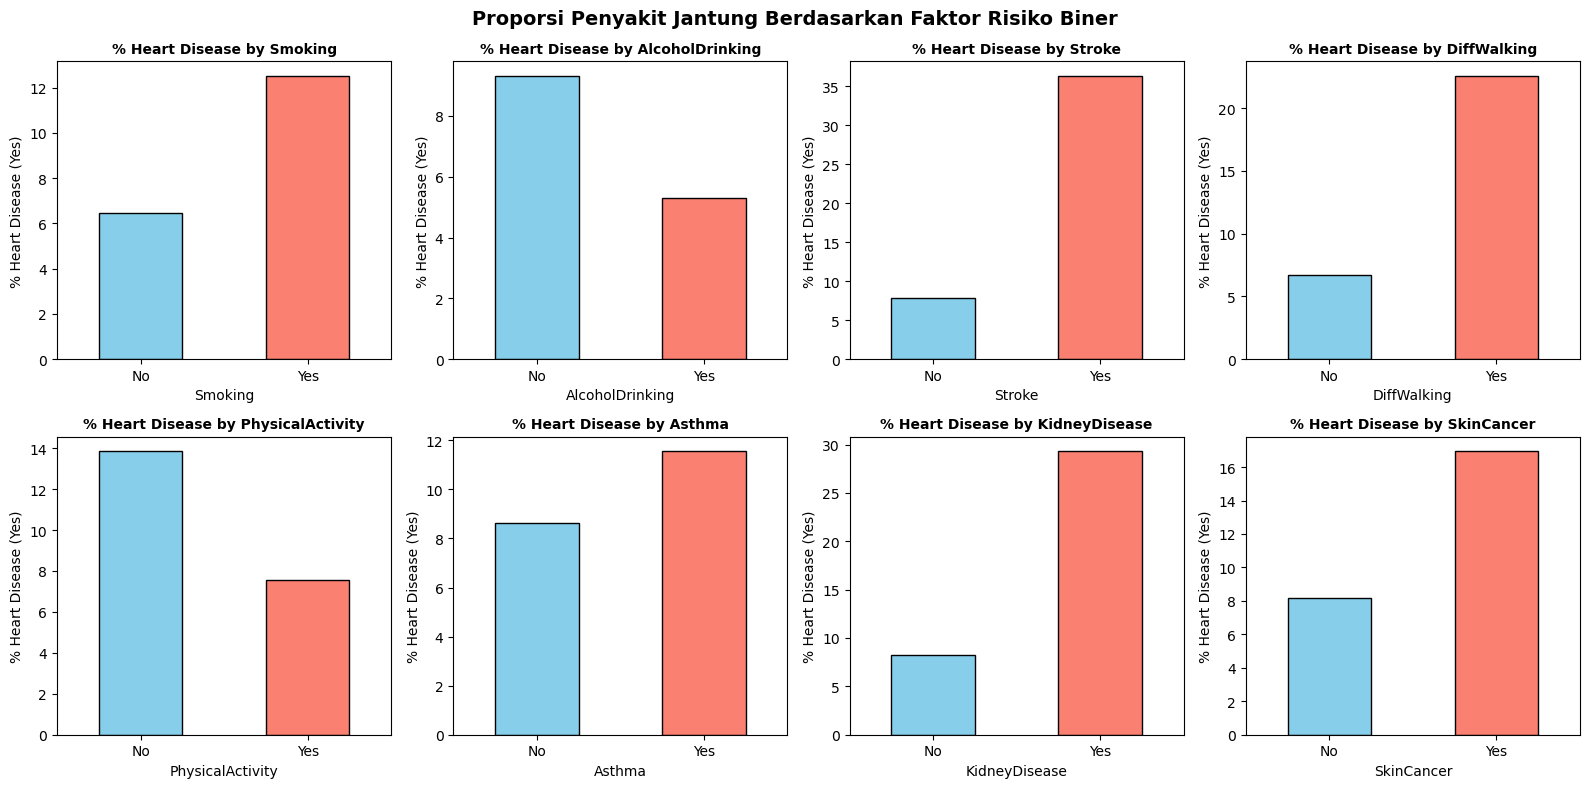

In [18]:
target_col= 'HeartDisease'
binary_cols= ['Smoking','AlcoholDrinking' ,'Stroke','DiffWalking' ,
               'PhysicalActivity','Asthma','KidneyDisease' ,'SkinCancer']
binary_cols =[c for c in binary_cols if c in df_clean.columns]

n=len(binary_cols)
ncols= 4
nrows=(n+ ncols-1)//ncols
fig , axes =plt.subplots(nrows , ncols,figsize =(16,4 *nrows))
axes = axes.flatten()

for i,col in enumerate(binary_cols) :
    ct=df_clean.groupby([col,target_col]).size().unstack(fill_value= 0)
    ct_pct = ct.div(ct.sum(axis = 1), axis=0) *100
    ct_pct['Yes'].plot(kind ='bar',ax =axes[i] ,color =['skyblue','salmon'] ,edgecolor='black')
    axes[i].grid(False)
    axes[i].set_facecolor('white')
    axes[i].set_title(f'% Heart Disease by {col}',fontsize = 10 , fontweight='bold')
    axes[i].set_ylabel('% Heart Disease (Yes)')
    axes[i].set_xlabel(col)
    axes[i].tick_params(axis='x', rotation = 0)

for j in range(i + 1,len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Proporsi Penyakit Jantung Berdasarkan Faktor Risiko Biner' ,fontsize= 14 , fontweight='bold')
plt.tight_layout()
plt.show()

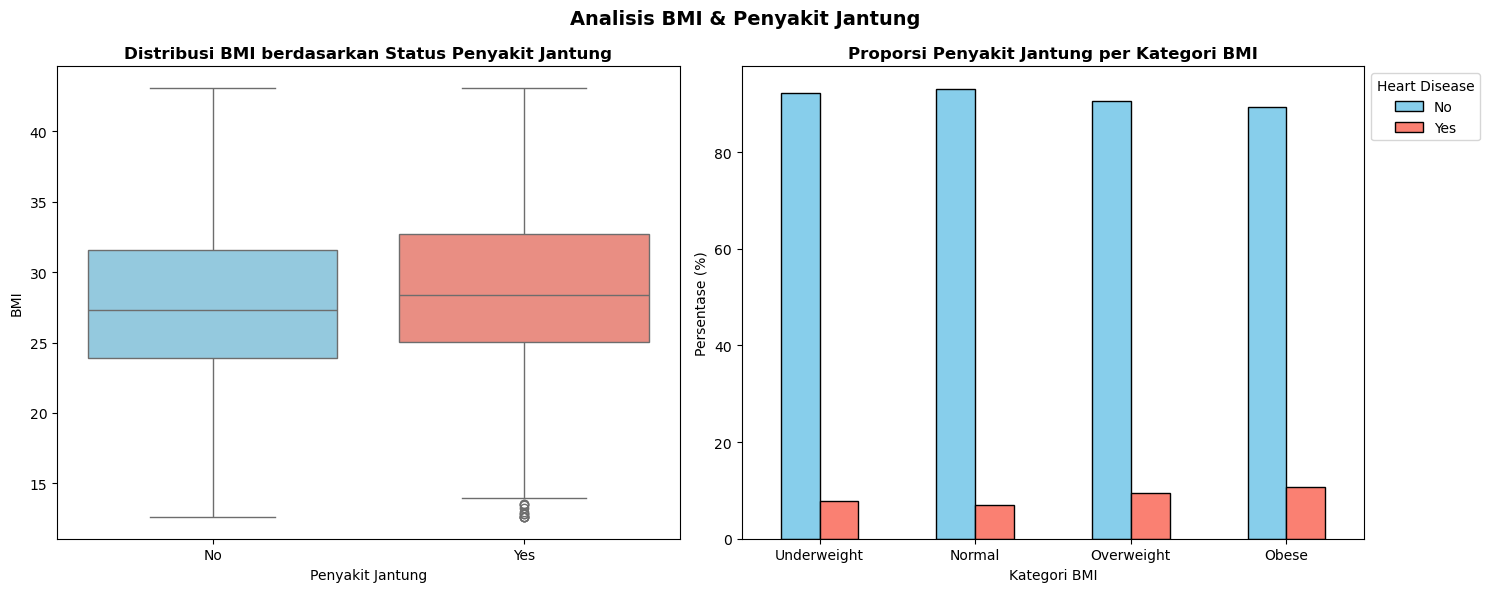

In [19]:
fig,axes=plt.subplots(1,2 ,figsize=(15, 6))
sns.boxplot(
    data=df_clean, x= target_col, y = 'BMI',
    palette= {'Yes' : 'salmon','No': 'skyblue'} ,
    ax= axes[0]
)
axes[0].grid(False)
axes[0].set_title('Distribusi BMI berdasarkan Status Penyakit Jantung' , fontweight = 'bold')
axes[0].set_xlabel('Penyakit Jantung')
axes[0].set_ylabel('BMI')

bmi_heart = df_clean.groupby(['BMI_Category' ,target_col]).size().unstack(fill_value = 0)
bmi_heart_pct= bmi_heart.div(bmi_heart.sum(axis =1) , axis =0)*100
bmi_order =['Underweight', 'Normal','Overweight' ,'Obese']
bmi_heart_pct =bmi_heart_pct.reindex(bmi_order)
bmi_heart_pct.plot(kind='bar' ,ax = axes[1],color=['skyblue' , 'salmon'],edgecolor='black')
axes[1].grid(False)
axes[1].set_title('Proporsi Penyakit Jantung per Kategori BMI' , fontweight='bold')
axes[1].set_xlabel('Kategori BMI')
axes[1].set_ylabel('Persentase (%)')
axes[1].legend(['No','Yes'] ,loc= 'upper left', bbox_to_anchor =(1 ,1),title='Heart Disease')
axes[1].tick_params(axis= 'x',rotation= 0)

plt.suptitle('Analisis BMI & Penyakit Jantung' , fontsize = 14 , fontweight ='bold')
plt.tight_layout()
plt.show()

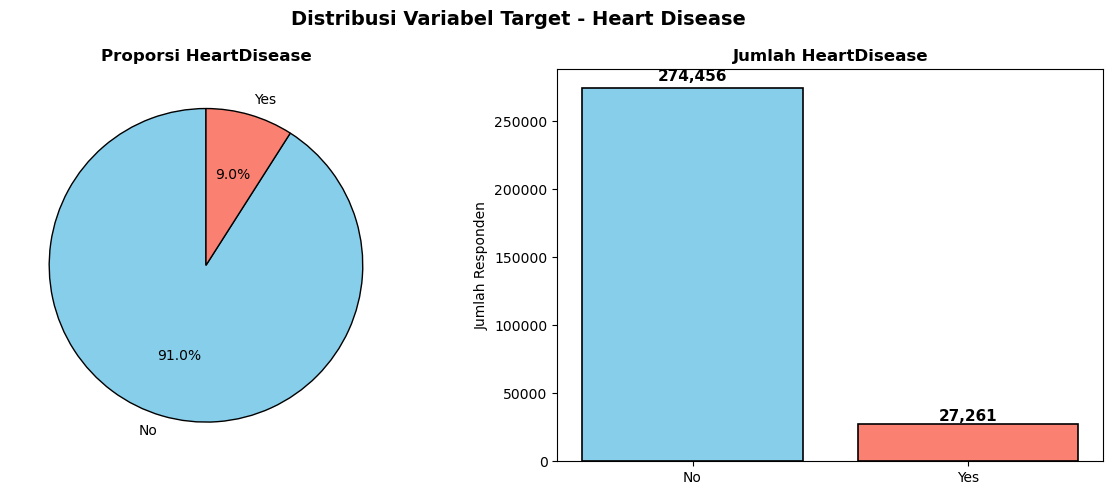

In [20]:
target_col='HadHeartAttack' if 'HadHeartAttack' in df_clean.columns else 'HeartDisease'
counts= df_clean[target_col].value_counts()

fig , axes = plt.subplots(1 , 2,figsize =(12 ,5))

axes[0].pie(counts , labels=counts.index , autopct='%1.1f%%',
            colors =['skyblue','salmon'],startangle= 90 ,
            wedgeprops= {'edgecolor' : 'black','linewidth' : 1})
axes[0].set_title(f'Proporsi {target_col}' ,fontweight= 'bold')

bars =axes[1].bar(counts.index, counts.values,color = ['skyblue' ,'salmon'],
                   edgecolor ='black', linewidth= 1.2)
axes[1].grid(False)
axes[1].set_facecolor('white')
axes[1].set_title(f'Jumlah {target_col}',fontweight ='bold')
axes[1].set_ylabel('Jumlah Responden')

for bar in bars:
    height =bar.get_height()
    axes[1].text(bar.get_x()+bar.get_width() / 2,height+ (height * 0.01) ,
                 f'{int(height):,}' , ha= 'center' ,va = 'bottom' , fontsize = 11,fontweight='bold')

plt.suptitle('Distribusi Variabel Target - Heart Disease' , fontsize= 14,fontweight = 'bold')
plt.tight_layout()
plt.show()

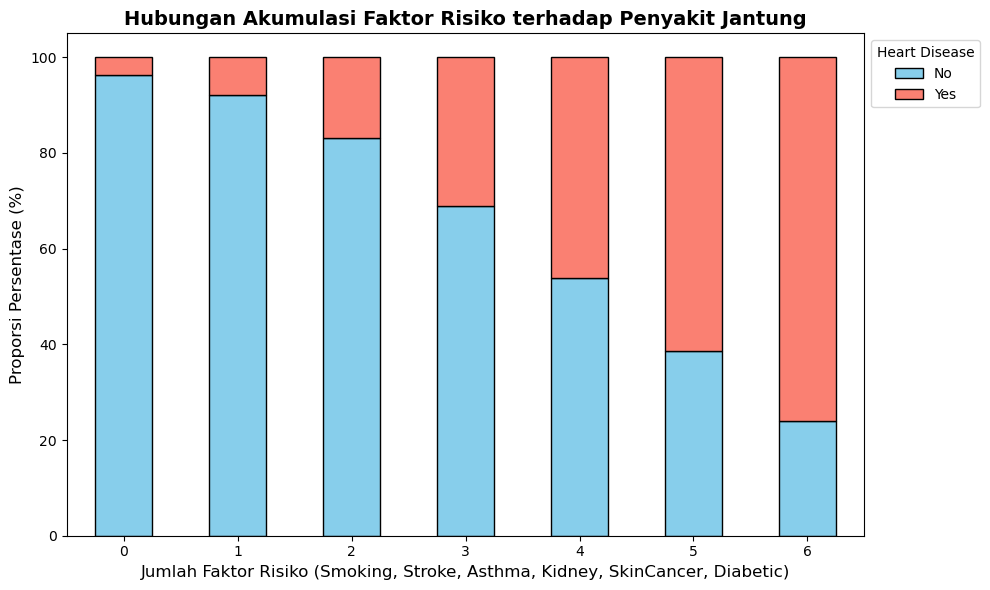

In [21]:
risk_trend = pd.crosstab(df_clean['Risk_Factor_Count'],df_clean['HeartDisease'] , normalize='index') *100
plt.figure(figsize =(10 ,6))
risk_trend.plot(kind='bar' , stacked = True , color =['skyblue' ,'salmon'] ,edgecolor= 'black' , ax=plt.gca())
plt.grid(False)
plt.gca().set_facecolor('white')
plt.title('Hubungan Akumulasi Faktor Risiko terhadap Penyakit Jantung',fontsize=14 ,fontweight='bold')
plt.xlabel('Jumlah Faktor Risiko (Smoking, Stroke, Asthma, Kidney, SkinCancer, Diabetic)', fontsize = 12)
plt.ylabel('Proporsi Persentase (%)',fontsize = 12)
plt.xticks(rotation=0)
plt.legend(title = 'Heart Disease' ,loc = 'upper left', bbox_to_anchor =(1, 1))
plt.tight_layout()
plt.show()

In [22]:
print("Evaluasi data")
print(f"Jumlah baris sebelum cleaning: {len(df)}")
print(f"Jumlah baris setelah cleaning: {len(df_clean)}")
print(f"Total baris (duplikat & outlier) yang dibuang: {len(df) - len(df_clean)}")

print("Pengecekan ulang nilai outlier (BMI)")
print(f"Nilai BMI Minimum sekarang: {df_clean['BMI'].min()}")
print(f"Nilai BMI Maksimum sekarang: {df_clean['BMI'].max()}")

Evaluasi data
Jumlah baris sebelum cleaning: 319795
Jumlah baris setelah cleaning: 301717
Total baris (duplikat & outlier) yang dibuang: 18078
Pengecekan ulang nilai outlier (BMI)
Nilai BMI Minimum sekarang: 12.600000000000005
Nilai BMI Maksimum sekarang: 43.08


In [23]:
age_gender_heart = pd.crosstab([df_clean['AgeCategory'], df_clean['Sex']] ,df_clean['HeartDisease'] , normalize= 'index') *100
print("Proporsi penyakjit jantung berdasarkan umur dan gender")
print(age_gender_heart.sort_values(by= 'Yes' ,ascending =False).head(10))

Proporsi penyakjit jantung berdasarkan umur dan gender
HeartDisease               No        Yes
AgeCategory Sex                         
80 or older Male    69.545898  30.454102
75-79       Male    73.542452  26.457548
70-74       Male    77.147193  22.852807
80 or older Female  81.479646  18.520354
65-69       Male    82.442440  17.557560
75-79       Female  85.972115  14.027885
60-64       Male    86.041639  13.958361
70-74       Female  88.783943  11.216057
55-59       Male    90.095136   9.904864
65-69       Female  91.282112   8.717888


In [24]:
df_all_corr =df_clean.copy()

age_order = {'18-24': 0,'25-29' : 1,'30-34' : 2, '35-39':3,'40-44' :4 , '45-49': 5 ,'50-54' :6 ,
             '55-59': 7 , '60-64' : 8 ,'65-69':9, '70-74' :10 , '75-79' : 11, '80 or older' :12}
gh_order = {'Poor' : 0, 'Fair' : 1 , 'Good':2 , 'Very good' : 3 ,'Excellent': 4}
df_all_corr['AgeCategory'] =df_all_corr['AgeCategory'].map(age_order)
df_all_corr['GenHealth'] = df_all_corr['GenHealth'].map(gh_order)

for col in df_all_corr.columns :
    if pd.api.types.is_string_dtype(df_all_corr[col]):
        values = df_all_corr[col].astype(str).str.strip().str.lower()
        if set(values.dropna().unique()).issubset({'yes', 'no'}) :
            df_all_corr[col]= values.map({'yes': 1,'no':0})
        else :
            df_all_corr[col] = pd.factorize(values)[0]

matriks_korelasi =df_all_corr.corr(method ='spearman')
print("nilai korelasi ke heart disease")
korelasi_heart_disease = matriks_korelasi['HeartDisease'].sort_values(ascending= False)
print(korelasi_heart_disease)

nilai korelasi ke heart disease
HeartDisease            1.000000
HeartDisease_Num        1.000000
AgeCategory             0.244840
Risk_Factor_Count       0.213673
DiffWalking             0.196420
Stroke                  0.194665
Stroke_Num              0.194665
Diabetic_Num            0.170331
KidneyDisease           0.142672
KidneyDisease_Num       0.142672
PhysicalHealth          0.135871
Smoking                 0.104524
Smoking_Num             0.104524
SkinCancer_Num          0.090644
SkinCancer              0.090644
Sex                     0.074435
BMI                     0.053687
BMI_Category            0.050621
Asthma                  0.035784
Asthma_Num              0.035784
SleepTime               0.010444
MentalHealth           -0.014347
AlcoholDrinking        -0.036289
Race                   -0.050269
PhysicalActivity       -0.093597
PhysicalActivity_Num   -0.093597
Diabetic               -0.157498
GenHealth              -0.221464
GenHealth_Num          -0.221464
Name: Heart

# Modeling - XGBoost

In [25]:
from sklearn.model_selection import train_test_split, GridSearchCV , StratifiedKFold
from sklearn.metrics import (classification_report , confusion_matrix, roc_auc_score ,
                             average_precision_score, f1_score, balanced_accuracy_score ,
                             precision_recall_curve, roc_curve)
import xgboost as xgb

In [26]:
df_model=df_clean.copy()

age_order = {'18-24':0 , '25-29':1, '30-34':2, '35-39' : 3, '40-44' :4 ,'45-49' :5, '50-54': 6,
             '55-59': 7, '60-64' :8 , '65-69' : 9 , '70-74' : 10,'75-79': 11 , '80 or older':12}
gh_order = {'Poor': 0, 'Fair' :1, 'Good': 2 , 'Very good': 3,'Excellent' :4}
df_model['AgeCategory']=df_model['AgeCategory'].map(age_order)
df_model['GenHealth'] = df_model['GenHealth'].map(gh_order)
df_model['Diabetic'] = df_model['Diabetic'].map({'Yes' :1 , 'Yes (during pregnancy)' :1 ,
                                                    'No' : 0 , 'No, borderline diabetes':0})

binary =['HeartDisease' ,'Smoking' , 'Stroke' , 'DiffWalking' , 'KidneyDisease','Asthma',
          'SkinCancer','AlcoholDrinking','PhysicalActivity']
for col in binary:
    df_model[col]= df_model[col].map({'Yes' :1,'No' :0})
df_model['Sex'] = (df_model['Sex']== 'Male').astype(int)

df_model['Risk_Factor_Count']=df_model[['Smoking','Stroke', 'Asthma','KidneyDisease' ,
                                          'SkinCancer' ,'Diabetic']].sum(axis= 1)

In [27]:
features=['AgeCategory','GenHealth', 'DiffWalking' , 'Stroke', 'PhysicalHealth' , 'MentalHealth',
            'Diabetic', 'KidneyDisease', 'Smoking', 'SkinCancer' , 'Asthma' ,'PhysicalActivity' ,
            'AlcoholDrinking','Sex', 'BMI', 'SleepTime','Risk_Factor_Count']
X= df_model[features].copy()
y = df_model['HeartDisease'].copy()
print(f"jumlah fitur: {len(features)}")

X_train,X_test, y_train ,y_test =train_test_split(X,y , test_size= 0.2,random_state= 42,stratify=y)
X_tr ,X_val,y_tr , y_val= train_test_split(X_train, y_train,test_size=0.2, random_state= 42, stratify= y_train)
print("train:" , X_tr.shape, "val:" , X_val.shape ,"test:" ,X_test.shape)

jumlah fitur: 17
train: (193098, 17) val: (48275, 17) test: (60344, 17)


In [28]:
scaler=StandardScaler()
num_cols= ['AgeCategory' ,'GenHealth' ,'PhysicalHealth' ,'MentalHealth' , 'BMI','SleepTime', 'Risk_Factor_Count']
X_tr[num_cols] = scaler.fit_transform(X_tr[num_cols].astype(float))
X_val[num_cols] = scaler.transform(X_val[num_cols].astype(float))
X_test[num_cols]= scaler.transform(X_test[num_cols].astype(float))

In [30]:
from itertools import product

spw = (y_tr == 0).sum() / (y_tr == 1).sum()
print(f"scale_pos_weight: {spw:.2f}")

param_grid = {
    'max_depth': [5, 7],
    'learning_rate': [0.05, 0.1],
    'n_estimators': [400, 600],
    'subsample': [0.9],
    'colsample_bytree': [0.8],
    'min_child_weight': [1]
}

def make_xgb(**p):
    return xgb.XGBClassifier(random_state=42, eval_metric='logloss', tree_method='hist',
                             scale_pos_weight=spw, n_jobs=4, **p)

skf = StratifiedKFold(3, shuffle=True, random_state=42)
results = []
for vals in product(*param_grid.values()):
    p = dict(zip(param_grid.keys(), vals))
    aucs = []
    for tr_idx, va_idx in skf.split(X_tr, y_tr):
        m = make_xgb(**p)
        m.fit(X_tr.iloc[tr_idx], y_tr.iloc[tr_idx])
        aucs.append(roc_auc_score(y_tr.iloc[va_idx], m.predict_proba(X_tr.iloc[va_idx])[:, 1]))
    results.append((np.mean(aucs), p))
    print(f"CV AUC {np.mean(aucs):.4f}  {p}")

best_score, best_params = max(results, key=lambda r: r[0])
best_xgb = make_xgb(**best_params).fit(X_tr, y_tr)
print("best params:", best_params)
print("CV ROC-AUC :", round(best_score, 4))

scale_pos_weight: 10.07
CV AUC 0.8364  {'max_depth': 5, 'learning_rate': 0.05, 'n_estimators': 400, 'subsample': 0.9, 'colsample_bytree': 0.8, 'min_child_weight': 1}
CV AUC 0.8343  {'max_depth': 5, 'learning_rate': 0.05, 'n_estimators': 600, 'subsample': 0.9, 'colsample_bytree': 0.8, 'min_child_weight': 1}
CV AUC 0.8314  {'max_depth': 5, 'learning_rate': 0.1, 'n_estimators': 400, 'subsample': 0.9, 'colsample_bytree': 0.8, 'min_child_weight': 1}
CV AUC 0.8274  {'max_depth': 5, 'learning_rate': 0.1, 'n_estimators': 600, 'subsample': 0.9, 'colsample_bytree': 0.8, 'min_child_weight': 1}
CV AUC 0.8275  {'max_depth': 7, 'learning_rate': 0.05, 'n_estimators': 400, 'subsample': 0.9, 'colsample_bytree': 0.8, 'min_child_weight': 1}
CV AUC 0.8216  {'max_depth': 7, 'learning_rate': 0.05, 'n_estimators': 600, 'subsample': 0.9, 'colsample_bytree': 0.8, 'min_child_weight': 1}
CV AUC 0.8143  {'max_depth': 7, 'learning_rate': 0.1, 'n_estimators': 400, 'subsample': 0.9, 'colsample_bytree': 0.8, 'min_chi

# Threshold tuning

In [31]:
val_proba=best_xgb.predict_proba(X_val)[: ,1]
prec ,rec , thr=precision_recall_curve(y_val , val_proba)
f1_scores = 2 *prec *rec/ (prec +rec+ 1e-9)

thr_balanced=thr[np.argmax(f1_scores[:- 1])]
ok =np.where(rec[ : - 1]>= 0.75)[0]
thr_screening= thr[ok[np.argmax(prec[: -1][ok])]] if len(ok) else thr_balanced

print(f"threshold balanced  (max F1) : {thr_balanced:.3f}")
print(f"threshold screening (rec>=.75): {thr_screening:.3f}")

threshold balanced  (max F1) : 0.732
threshold screening (rec>=.75): 0.550


In [32]:
test_proba = best_xgb.predict_proba(X_test)[: , 1]

print(f"ROC-AUC : {roc_auc_score(y_test, test_proba):.3f}")
print(f"PR-AUC  : {average_precision_score(y_test, test_proba):.3f}")

for nama,t in [('THRESHOLD SCREENING', thr_screening) ,('THRESHOLD BALANCED' ,thr_balanced)]:
    y_pred= (test_proba >= t).astype(int)
    print(f"\n{nama} (t={t:.3f})")
    print(classification_report(y_test , y_pred , target_names = ['sehat(no)','sakit jantung(yes)'] ,digits=3))
    print(f"accuracy     : {(y_pred==y_test).mean():.3f}")
    print(f"balanced acc : {balanced_accuracy_score(y_test, y_pred):.3f}")

ROC-AUC : 0.835
PR-AUC  : 0.346

THRESHOLD SCREENING (t=0.550)
                    precision    recall  f1-score   support

         sehat(no)      0.968     0.764     0.854     54892
sakit jantung(yes)      0.240     0.749     0.363      5452

          accuracy                          0.762     60344
         macro avg      0.604     0.757     0.609     60344
      weighted avg      0.903     0.762     0.810     60344

accuracy     : 0.762
balanced acc : 0.757

THRESHOLD BALANCED (t=0.732)
                    precision    recall  f1-score   support

         sehat(no)      0.946     0.905     0.925     54892
sakit jantung(yes)      0.331     0.476     0.391      5452

          accuracy                          0.866     60344
         macro avg      0.638     0.690     0.658     60344
      weighted avg      0.890     0.866     0.876     60344

accuracy     : 0.866
balanced acc : 0.690


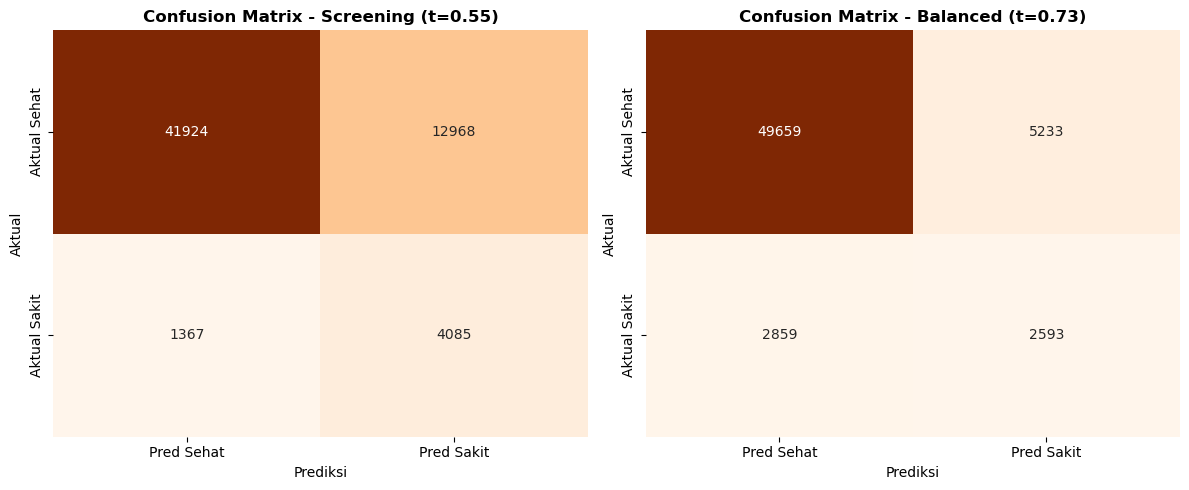

In [33]:
fig, axes=plt.subplots(1,2,figsize= (12 ,5))
for ax ,(nama , t) in zip(axes, [('Screening' , thr_screening),('Balanced',thr_balanced)]):
    y_pred = (test_proba >= t).astype(int)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm , annot=True , fmt= 'd', cmap = 'Oranges',cbar =False ,
                xticklabels =['Pred Sehat', 'Pred Sakit'],
                yticklabels= ['Aktual Sehat' , 'Aktual Sakit'] ,ax =ax)
    ax.set_title(f'Confusion Matrix - {nama} (t={t:.2f})',fontweight='bold')
    ax.set_ylabel('Aktual'); ax.set_xlabel('Prediksi')
plt.tight_layout(); plt.show()

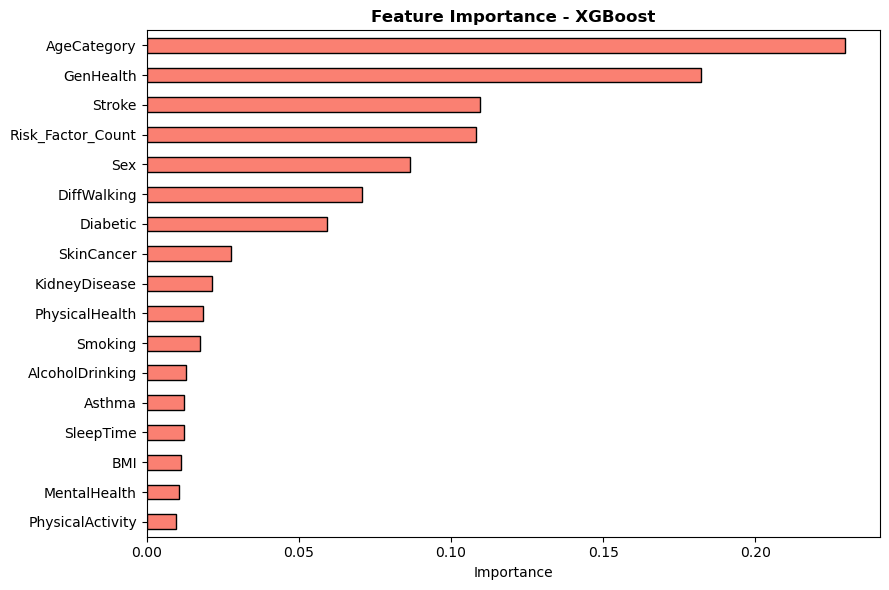

AgeCategory          0.2295
GenHealth            0.1821
Stroke               0.1095
Risk_Factor_Count    0.1084
Sex                  0.0865
DiffWalking          0.0706
Diabetic             0.0592
SkinCancer           0.0276
KidneyDisease        0.0215
PhysicalHealth       0.0185
Smoking              0.0176
AlcoholDrinking      0.0129
Asthma               0.0123
SleepTime            0.0122
BMI                  0.0112
MentalHealth         0.0107
PhysicalActivity     0.0097


In [34]:
imp=pd.Series(best_xgb.feature_importances_,index =features).sort_values(ascending=False)
plt.figure(figsize= (9, 6))
imp.plot(kind= 'barh', color = 'salmon' , edgecolor='black')
plt.gca().invert_yaxis()
plt.title('Feature Importance - XGBoost' ,fontweight= 'bold')
plt.xlabel('Importance'); plt.tight_layout(); plt.show()
print(imp.round(4).to_string())

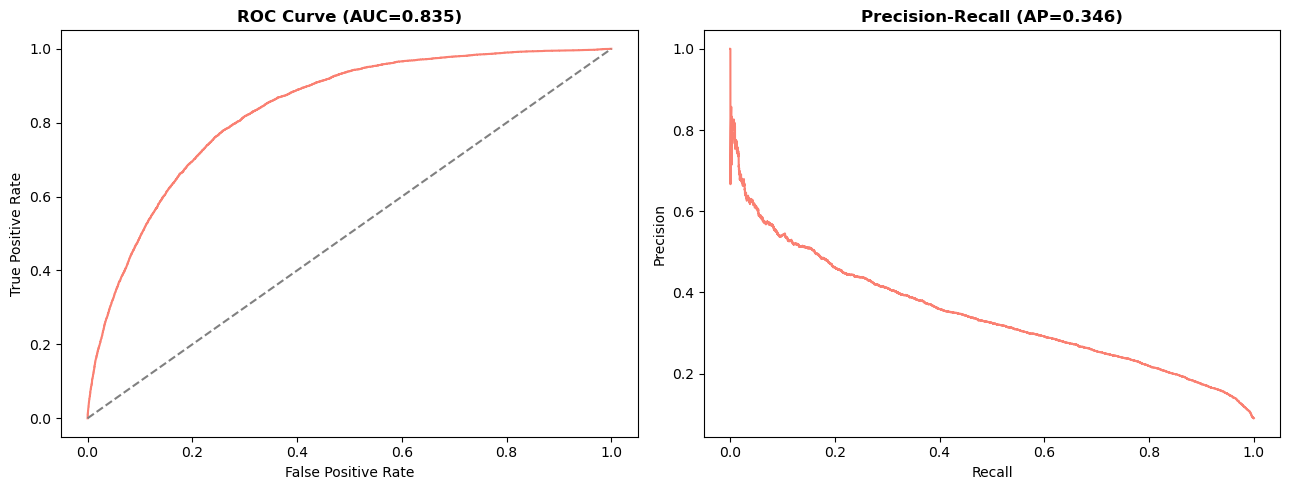

In [35]:
fpr, tpr ,_ = roc_curve(y_test,test_proba)
prec_c,rec_c ,_=precision_recall_curve(y_test,test_proba)
fig, axes =plt.subplots(1 , 2,figsize= (13 , 5))
axes[0].plot(fpr,tpr,color ='salmon'); axes[0].plot([0 , 1],[0 , 1], '--',color= 'gray')
axes[0].set_title(f'ROC Curve (AUC={roc_auc_score(y_test,test_proba):.3f})' ,fontweight='bold')
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[1].plot(rec_c, prec_c,color= 'salmon')
axes[1].set_title(f'Precision-Recall (AP={average_precision_score(y_test,test_proba):.3f})' , fontweight='bold')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
plt.tight_layout(); plt.show()